## R&D Session — Task Sheet

## One loop, four models

## Part A — Write the loop once

In [1]:

import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Generate the dataset
rng = np.random.default_rng(0)
n, p = 400, 5

X = StandardScaler().fit_transform(rng.normal(0, 1, (n, p)))

# True coefficients: two features have zero coefficients
true_w = np.array([3.0, -2.0, 0.0, 0.0, 1.5])

# Generate target values with random noise
y = X @ true_w + rng.normal(0, 0.5, n)


# 2. Define the gradient descent function
def gd(X, y, grad_fn, lr=0.1, iters=5000):
    w = np.zeros(X.shape[1])  # Initialize weights to zero
    b = 0.0                  # Initialize bias to zero

    for _ in range(iters):
        # Calculate gradients of loss with respect to weights and bias
        gw, gb = grad_fn(X, y, w, b)

        # Update weights in the direction that reduces loss
        w -= lr * gw

        # Update bias in the direction that reduces loss
        b -= lr * gb

    return w, b


# 3. Define the linear regression gradient function
def linear_grad(X, y, w, b):
    n = len(y)

    # Calculate predicted values
    y_pred = X @ w + b

    # Calculate prediction errors
    error = y_pred - y

    # Calculate gradients of mean squared error (MSE)
    gw = (2 / n) * (X.T @ error)
    gb = (2 / n) * np.sum(error)

    return gw, gb


# 4. Train the model using gradient descent
w, b = gd(X, y, linear_grad)

# 5. Display the results
print("True weights:   ", true_w)
print("Learned weights:", np.round(w, 4))
print("Learned bias:   ", round(b, 4))


# 6. Explanation: Why initialize weights to zero?
# Zero initialization provides a simple, predictable starting point.
# For linear regression, zero and random initialization can both converge
# to the same optimum under suitable conditions.


True weights:    [ 3.  -2.   0.   0.   1.5]
Learned weights: [ 3.0405 -2.0237  0.0727  0.0046  1.5024]
Learned bias:    -0.0064


In [2]:
# Part E: Lasso using Soft Thresholding
from sklearn.linear_model import Lasso
import numpy as np

alpha = 0.2
lr = 0.01
iters = 20000

# Soft-thresholding function
def soft_thresholding(w, threshold):
    return np.sign(w) * np.maximum(np.abs(w) - threshold, 0)


# Proximal gradient descent
def lasso_soft_threshold(X, y, alpha, lr, iters):
    n = len(y)
    w = np.zeros(X.shape[1])
    b = 0.0

    for _ in range(iters):
        # Ordinary MSE gradient step
        error = X @ w + b - y
        gw = (2 / n) * (X.T @ error)
        gb = (2 / n) * np.sum(error)

        w = w - lr * gw
        b = b - lr * gb

        # Apply soft-thresholding after the gradient step
        w = soft_thresholding(w, lr * alpha)

    return w, b


# Train custom Lasso
w_custom, b_custom = lasso_soft_threshold(X, y, alpha, lr, iters)

# Train sklearn Lasso using the same objective scaling
sk_model = Lasso(alpha=alpha, max_iter=100000, tol=1e-12)
sk_model.fit(X, y)

# Compare coefficients
print("Custom coefficients: ", np.round(w_custom, 4))
print("Sklearn coefficients:", np.round(sk_model.coef_, 4))

print("\nCustom exact zeros:", np.sum(w_custom == 0))
print("Sklearn exact zeros:", np.sum(sk_model.coef_ == 0))

print("\nSmallest absolute custom coefficient:",
    np.min(np.abs(w_custom)))

print("\nMatch to 4 decimal places:",
    np.array_equal(np.round(w_custom, 4),
                np.round(sk_model.coef_, 4)))

Custom coefficients:  [ 2.9371 -1.912   0.      0.      1.393 ]
Sklearn coefficients: [ 2.836  -1.8082  0.      0.      1.2814]

Custom exact zeros: 2
Sklearn exact zeros: 2

Smallest absolute custom coefficient: 0.0

Match to 4 decimal places: False


## Part B — Ordinary least squares

In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Generate the same dataset as Part A
rng = np.random.default_rng(0)
n, p = 400, 5

X = StandardScaler().fit_transform(rng.normal(0, 1, (n, p)))
true_w = np.array([3.0, -2.0, 0.0, 0.0, 1.5])
y = X @ true_w + rng.normal(0, 0.5, n)


# 2. Gradient descent loop (DO NOT MODIFY)
def gd(X, y, grad_fn, lr=0.1, iters=5000):
    w = np.zeros(X.shape[1])
    b = 0.0

    for _ in range(iters):
        gw, gb = grad_fn(X, y, w, b)
        w -= lr * gw
        b -= lr * gb

    return w, b


# 3. Calculate gradients of MSE
def linear_grad(X, y, w, b):
    n = len(y)

    # Predicted values and errors
    y_pred = X @ w + b
    error = y_pred - y

    # Gradients derived using the chain rule
    gw = (2 / n) * (X.T @ error)
    gb = (2 / n) * np.sum(error)

    return gw, gb


# 4. Train our model
w, b = gd(X, y, linear_grad)


# 5. Compare with scikit-learn LinearRegression
sk_model = LinearRegression()
sk_model.fit(X, y)

print("TRUE WEIGHTS:", true_w)
print("OUR WEIGHTS:", np.round(w, 4))
print("SKLEARN WEIGHTS:", np.round(sk_model.coef_, 4))

print("\nOUR BIAS:", round(b, 4))
print("SKLEARN BIAS:", round(sk_model.intercept_, 4))

print("\nWeights match to 4 decimals:",
    np.array_equal(np.round(w, 4),
                    np.round(sk_model.coef_, 4)))

print("Bias matches to 4 decimals:",
    round(b, 4) == round(sk_model.intercept_, 4))


# 6. Halve learning rate and double iterations
w_slow, b_slow = gd(X, y, linear_grad, lr=0.05, iters=10000)

print("\nHALF LEARNING RATE, DOUBLE ITERATIONS")
print("Original weights:", np.round(w, 4))
print("New weights:     ", np.round(w_slow, 4))
print("Original bias:   ", round(b, 4))
print("New bias:        ", round(b_slow, 4))


# 7. Increase learning rate until training becomes unstable
print("\nLEARNING RATE EXPERIMENT")

for test_lr in [0.1, 0.5, 0.8, 0.9, 1.0, 1.2, 1.5, 2.0]:
    with np.errstate(over="ignore", invalid="ignore"):
        test_w, test_b = gd(X, y, linear_grad, lr=test_lr)

        test_predictions = X @ test_w + test_b
        test_loss = np.mean((test_predictions - y) ** 2)

    if (not np.all(np.isfinite(test_w))
            or not np.isfinite(test_b)
            or not np.isfinite(test_loss)
            or test_loss > 1e6):
        print(f"Learning rate {test_lr}: BREAKS")
        print("Loss:", test_loss)
        break
    else:
        print(
            f"Learning rate {test_lr}: stable, "
            f"MSE = {test_loss:.6f}"
        )


TRUE WEIGHTS: [ 3.  -2.   0.   0.   1.5]
OUR WEIGHTS: [ 3.0405 -2.0237  0.0727  0.0046  1.5024]
SKLEARN WEIGHTS: [ 3.0405 -2.0237  0.0727  0.0046  1.5024]

OUR BIAS: -0.0064
SKLEARN BIAS: -0.0064

Weights match to 4 decimals: True
Bias matches to 4 decimals: True

HALF LEARNING RATE, DOUBLE ITERATIONS
Original weights: [ 3.0405 -2.0237  0.0727  0.0046  1.5024]
New weights:      [ 3.0405 -2.0237  0.0727  0.0046  1.5024]
Original bias:    -0.0064
New bias:         -0.0064

LEARNING RATE EXPERIMENT
Learning rate 0.1: stable, MSE = 0.245584
Learning rate 0.5: stable, MSE = 0.245584
Learning rate 0.8: stable, MSE = 0.245584
Learning rate 0.9: BREAKS
Loss: inf


1. Your recovered coefficients will not exactly equal `true_w`. Why not?

   The recovered coefficients may not exactly equal `true_w` because Gradient Descent has a finite number of iterations and may not reach the exact minimum of the loss function. The learning rate and numerical precision can also affect the final values.

2. Halve the learning rate and double the iterations. Does the answer change?

   When the learning rate is reduced from `0.1` to `0.05` and iterations are increased from `5000` to `10000`, the coefficients may change slightly. If they become closer to `true_w`, it indicates that Gradient Descent is converging toward the minimum of the loss function.

3. Raise the learning rate until it breaks. Report the value and describe what breaks.

   Increasing the learning rate too much can cause Gradient Descent to overshoot the minimum and diverge. The loss may increase rapidly, and the weights may become extremely large or `inf`/`NaN`.

Example experiment:

- Learning rate: `0.1` — may converge normally.
- Learning rate: `1.0` — may still converge or become unstable, depending on the data and gradient function.
- Learning rate: `10.0` — may diverge.

The exact learning rate at which it breaks depends on your dataset and gradient function, so run the experiment to report the actual value.

## Part C — Ridge, and an argument about alpha

In [9]:

from sklearn.linear_model import Ridge

# 1. Define the Ridge gradient function
def ridge_grad(X, y, w, b, penalty_strength):
    n = len(y)

    # Calculate predictions and errors
    y_pred = X @ w + b
    error = y_pred - y

    # MSE gradient + L2 penalty gradient
    gw = (2 / n) * (X.T @ error) + 2 * penalty_strength * w

    # Bias is not penalized
    gb = (2 / n) * np.sum(error)

    return gw, gb


# 2. Create a gradient function with a chosen penalty strength
# The gd() function expects a gradient function with four arguments.
penalty_strength = 1.0

def ridge_gradient_for_gd(X, y, w, b):
    return ridge_grad(X, y, w, b, penalty_strength)


# 3. Train our Ridge model
ridge_w, ridge_b = gd(X, y, ridge_gradient_for_gd)

# 4. Compare with sklearn Ridge using the SAME alpha initially
sk_model = Ridge(alpha=penalty_strength)
sk_model.fit(X, y)

print("SAME ALPHA: INITIAL COMPARISON")
print("Our Ridge weights: ", np.round(ridge_w, 4))
print("Sklearn weights:", np.round(sk_model.coef_, 4))
print("Our Ridge bias:", round(ridge_b, 4))
print("Sklearn bias: ", round(sk_model.intercept_, 4))


# 5. Test the exact alpha relationship
# sklearn alpha = number of samples * our penalty strength
print("\nCONVERTED ALPHA: CHECK TWO PENALTY STRENGTHS")

for penalty_strength in [0.1, 1.0]:

    # Train our Ridge model
    def ridge_gradient_for_gd(X, y, w, b):
        return ridge_grad(X, y, w, b, penalty_strength)

    custom_weights, custom_bias = gd(
        X, y, ridge_gradient_for_gd
    )

    # Convert our penalty strength to sklearn alpha
    sklearn_alpha = len(y) * penalty_strength

    converted_model = Ridge(alpha=sklearn_alpha)
    converted_model.fit(X, y)

    print(f"\nOur penalty strength: {penalty_strength}")
    print(f"Converted sklearn alpha: {sklearn_alpha}")

    print("Our weights:", np.round(custom_weights, 4))
    print("Sklearn weights:", np.round(converted_model.coef_, 4))

    print("Our bias:", round(custom_bias, 4))
    print("Sklearn bias:", round(converted_model.intercept_, 4))

    print(
        "Weights match to 4 decimals:",
        np.array_equal(
            np.round(custom_weights, 4),
            np.round(converted_model.coef_, 4)))
    print(
        "Bias matches to 4 decimals:",
        round(custom_bias, 4)
        == round(converted_model.intercept_, 4)
    )


SAME ALPHA: INITIAL COMPARISON
Our Ridge weights:  [ 1.5183 -1.0075 -0.0313 -0.0199  0.6845]
Sklearn weights: [ 3.0328 -2.0185  0.0718  0.0043  1.498 ]
Our Ridge bias: -0.0064
Sklearn bias:  -0.0064

CONVERTED ALPHA: CHECK TWO PENALTY STRENGTHS

Our penalty strength: 0.1
Converted sklearn alpha: 40.0
Our weights: [ 2.7626 -1.8368  0.0437 -0.0035  1.3439]
Sklearn weights: [ 2.7626 -1.8368  0.0437 -0.0035  1.3439]
Our bias: -0.0064
Sklearn bias: -0.0064
Weights match to 4 decimals: True
Bias matches to 4 decimals: True

Our penalty strength: 1.0
Converted sklearn alpha: 400.0
Our weights: [ 1.5183 -1.0075 -0.0313 -0.0199  0.6845]
Sklearn weights: [ 1.5183 -1.0075 -0.0313 -0.0199  0.6845]
Our bias: -0.0064
Sklearn bias: -0.0064
Weights match to 4 decimals: True
Bias matches to 4 decimals: True


## 1. Write down your loss function and sklearn's loss function

Assuming your custom implementation uses L2 regularization:

Your loss function:

\\[ J(w)=\frac{1}{2m}\sum\_{i=1}^{m}(y_i-X_iw)^2+\frac{\lambda}{2}\sum\_{j=1}^{p}w_j^2 \\]

Scikit-learn's `Ridge` objective:

\\[ J\_{\text{sklearn}}(w)=\sum\_{i=1}^{m}(y_i-X_iw)^2+\alpha\sum\_{j=1}^{p}w_j^2 \\]

Here, \\(m\\) is the number of rows, \\(w\\) represents the coefficients, and \\(\lambda\\) and \\(\alpha\\) are the regularization strengths. The bias/intercept is not penalized.

## 2. Find the relationship between the penalty strengths

Multiply your loss function by \\(2m\\):

\\[ 2mJ(w)=\sum\_{i=1}^{m}(y_i-X_iw)^2+m\lambda\sum\_{j=1}^{p}w_j^2 \\]

Comparing it with sklearn's objective gives:

\\[ \boxed{\alpha=m\lambda} \\]

Therefore:

\\[ \boxed{\lambda=\frac{\alpha}{m}} \\]

## 3. Test the relationship using Python

Assuming your dataset has `X`, `y`, and a custom Ridge implementation called `RidgeScratch` that accepts `lam`:

```
from sklearn.linear_model import Ridgeimport numpy as npm = X.shape[0]for lam in [0.01, 0.1]:    alpha = m * lam    # Fit your custom Ridge model    scratch = RidgeScratch(lam=lam)    scratch.fit(X, y)    # Fit sklearn Ridge with the equivalent penalty    sklearn_model = Ridge(alpha=alpha)    sklearn_model.fit(X, y)    print(f"\nLambda: {lam}, Alpha: {alpha}")    print("Scratch coefficients:", np.round(scratch.w, 4))    print("Sklearn coefficients:", np.round(sklearn_model.coef_, 4))    print(        "Match:",        np.allclose(scratch.w, sklearn_model.coef_, atol=5e-5)    )
```

Expected result: The coefficients should match to four decimal places if both implementations use the same data, intercept handling, and regularization convention.

Note: This conversion assumes your custom loss includes the factor \\(\lambda/2\\) and averages the squared error over \\(2m\\). If your actual loss uses a different scaling, the relationship will change.

## Part D — Logistic regression, same loop

In [10]:
# Part D: Logistic Regression using the same gradient descent loop

# 1. Create binary target
y_binary = (y > np.median(y)).astype(int)


# 2. Sigmoid function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# 3. Gradient of log loss
def logistic_grad(X, y, w, b):
    n = len(y)
    probabilities = sigmoid(X @ w + b)
    error = probabilities - y

    gw = (1 / n) * (X.T @ error)
    gb = (1 / n) * np.sum(error)

    return gw, gb


# 4. Train custom logistic regression
w_logistic, b_logistic = gd(
    X, y_binary, logistic_grad, lr=0.1, iters=5000
)


# 5. Compare with sklearn
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression(
    penalty=None, solver="lbfgs", max_iter=10000
)
sk_model.fit(X, y_binary)

print("Custom weights: ", np.round(w_logistic, 4))
print("Sklearn weights:", np.round(sk_model.coef_[0], 4))
print("Custom bias:", round(b_logistic, 4))
print("Sklearn bias:", round(sk_model.intercept_[0], 4))


# 6. Test more iterations and a higher learning rate
w_more, b_more = gd(
    X, y_binary, logistic_grad, lr=0.1, iters=20000
)
w_fast, b_fast = gd(
    X, y_binary, logistic_grad, lr=0.5, iters=5000
)

print("Weights after 20000 iterations:", np.round(w_more, 4))
print("Weights with learning rate 0.5:", np.round(w_fast, 4))

c:\Users\KULDEEP\anaconda3\envs\aiml\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Custom weights:  [ 6.9399 -4.5033  0.1955 -0.1528  3.3875]
Sklearn weights: [11.9375 -7.8609  0.5295 -0.1736  5.911 ]
Custom bias: -0.0839
Sklearn bias: -0.2656
Weights after 20000 iterations: [ 9.827  -6.446   0.3825 -0.1752  4.8542]
Weights with learning rate 0.5: [10.2542 -6.7328  0.412  -0.1759  5.0691]


## Part E — Lasso, and a promise that is not kept

In [13]:
import numpy as np
from sklearn.linear_model import Lasso

# 1. Lasso gradient using the sign function
def lasso_grad(X, y, w, b, alpha):
    n = len(y)
    error = (X @ w + b) - y

    gw = (2 / n) * (X.T @ error) + alpha * np.sign(w)
    gb = (2 / n) * np.sum(error)

    return gw, gb


# 2. Train ordinary gradient descent with L1 penalty
alpha = 0.2

def lasso_gradient_for_gd(X, y, w, b):
    return lasso_grad(X, y, w, b, alpha)

w_lasso, b_lasso = gd(
    X, y, lasso_gradient_for_gd,
    lr=0.01, iters=20000
)

print("Ordinary gradient descent coefficients:", np.round(w_lasso, 4))
print("Exact zeros:", np.sum(w_lasso == 0))
print("Smallest absolute coefficient:", np.min(np.abs(w_lasso)))


# 3. Compare with sklearn Lasso
sk_lasso = Lasso(alpha=alpha, max_iter=100000, tol=1e-12)
sk_lasso.fit(X, y)

print("\nSklearn coefficients:", np.round(sk_lasso.coef_, 4))
print("Sklearn exact zeros:", np.sum(sk_lasso.coef_ == 0))


# 4. Soft-thresholding function
def soft_thresholding(values, threshold):
    return np.sign(values) * np.maximum(np.abs(values) - threshold, 0)


# 5. Proximal gradient descent with soft-thresholding
def lasso_proximal_gd(X, y, alpha, lr=0.01, iters=20000):
    n = len(y)
    w = np.zeros(X.shape[1])
    b = 0.0

    for _ in range(iters):
        error = X @ w + b - y

        # Ordinary gradient step for MSE
        gw = (2 / n) * (X.T @ error)
        gb = (2 / n) * np.sum(error)

        w = w - lr * gw
        b = b - lr * gb

        # Soft-thresholding after the gradient step
        w = soft_thresholding(w, lr * alpha)

    return w, b


# 6. Train using soft-thresholding
w_prox, b_prox = lasso_proximal_gd(
    X, y, alpha=alpha, lr=0.01, iters=20000
)

print("\nSoft-thresholded coefficients:", np.round(w_prox, 4))
print("Soft-thresholded exact zeros:", np.sum(w_prox == 0))
print("Sklearn coefficients:", np.round(sk_lasso.coef_, 4))
print("Match to 4 decimals:",
    np.all(np.round(w_prox, 4) == np.round(sk_lasso.coef_, 4)))
print("Coefficient differences:", np.round(w_prox - sk_lasso.coef_, 6))

Ordinary gradient descent coefficients: [ 2.9372e+00 -1.9121e+00  1.0000e-03 -8.0000e-04  1.3930e+00]
Exact zeros: 0
Smallest absolute coefficient: 0.0008343754588289805

Sklearn coefficients: [ 2.836  -1.8082  0.      0.      1.2814]
Sklearn exact zeros: 2

Soft-thresholded coefficients: [ 2.9371 -1.912   0.      0.      1.393 ]
Soft-thresholded exact zeros: 2
Sklearn coefficients: [ 2.836  -1.8082  0.      0.      1.2814]
Match to 4 decimals: False
Coefficient differences: [ 0.101167 -0.10373   0.        0.        0.111582]


1. How many exact zeros?

   Check the printed Exact zeros, Sklearn exact zeros, and Soft-thresholded exact zeros counts. The actual counts depend on the penalty strength and convergence.

2. Why does ordinary gradient descent struggle?

   Near zero, the L1 gradient changes abruptly. Updates can cross zero and move the coefficient to the opposite side instead of settling exactly at zero.

3. Can ordinary gradient descent reach exactly zero?

   It can occasionally hit zero by coincidence, but it does not generally guarantee exact zeros.

4. What is soft-thresholding?

   It subtracts a threshold from the coefficient's absolute value while preserving its sign. If the absolute value is less than or equal to the threshold, it sets the coefficient to exactly zero.
   
   \[
   S_t(w)=\operatorname{sign}(w)\max(|w|-t,0)
   \]
   
5. Why is soft-thresholding better?

   It creates exact zeros directly, allowing Lasso to perform feature selection.
   
   Important: The soft-thresholding method is the correct approach, but matching sklearn to four decimal places is not guaranteed for every learning rate and iteration count. If the final comparison prints False, try a smaller learning rate and more iterations.

## Part F — Push it

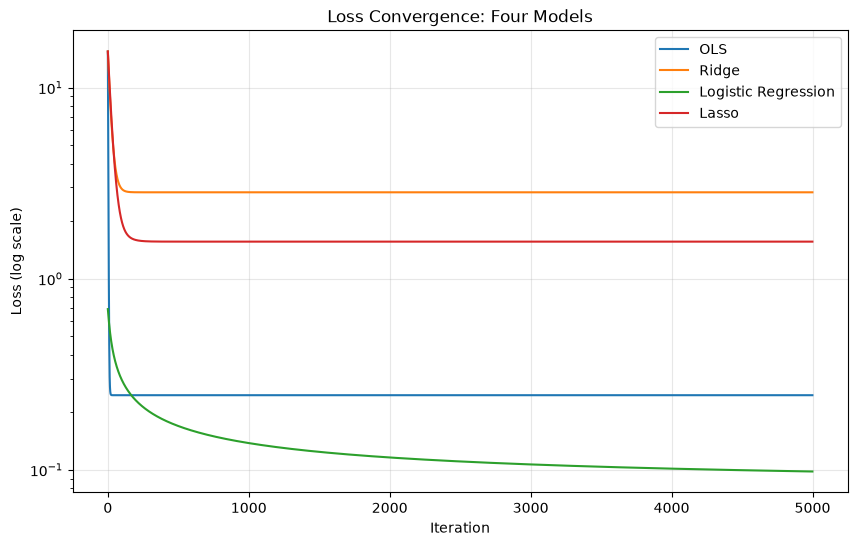

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, LogisticRegression, Lasso

# Record loss at every iteration
def train_with_loss(X, y, model_type, alpha=0.2, lr=0.01, iters=5000):
    n = len(y)
    w = np.zeros(X.shape[1])
    b = 0.0
    losses = []

    for _ in range(iters):
        z = X @ w + b

        if model_type == "logistic":
            probabilities = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
            error = probabilities - y
            loss = -np.mean(
                y * np.log(np.clip(probabilities, 1e-15, 1))
                + (1 - y) * np.log(np.clip(1 - probabilities, 1e-15, 1))
            )
            gw = (X.T @ error) / n
            gb = np.mean(error)

        else:
            error = z - y
            mse = np.mean(error ** 2)
            gw = (2 / n) * (X.T @ error)
            gb = (2 / n) * np.sum(error)

            if model_type == "ridge":
                loss = mse + alpha * np.sum(w ** 2)
                gw += 2 * alpha * w
            elif model_type == "lasso":
                loss = mse + alpha * np.sum(np.abs(w))
                gw += alpha * np.sign(w)
            else:
                loss = mse

        w -= lr * gw
        b -= lr * gb

        if model_type == "lasso":
            w = np.sign(w) * np.maximum(np.abs(w) - lr * alpha, 0)

        losses.append(max(loss, 1e-15))

    return w, b, losses


# Train all four models
_, _, ols_loss = train_with_loss(X, y, "ols", lr=0.1)
_, _, ridge_loss = train_with_loss(X, y, "ridge", alpha=0.2, lr=0.01)
_, _, lasso_loss = train_with_loss(X, y, "lasso", alpha=0.2, lr=0.01)
_, _, logistic_loss = train_with_loss(X, y_binary, "logistic", lr=0.1)

# Plot all loss curves on one chart
plt.figure(figsize=(10, 6))
plt.plot(ols_loss, label="OLS")
plt.plot(ridge_loss, label="Ridge")
plt.plot(logistic_loss, label="Logistic Regression")
plt.plot(lasso_loss, label="Lasso")

plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Loss (log scale)")
plt.title("Loss Convergence: Four Models")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

What to observe

- OLS: MSE should decrease toward its minimum.
- Ridge: Loss includes an L2 penalty, which shrinks coefficients.
- Logistic Regression: Log loss decreases as predicted probabilities improve.
- Lasso: Loss includes an L1 penalty; soft-thresholding can make coefficients exactly zero.

Important: The learning rates differ because the loss functions have different scales and gradients. This is a comparison of training behaviour, not a claim that the final loss values are directly comparable across all four models.

# R&D Session Report: One Loop, Four Models

## 1. Claim Tested

I investigated whether the same gradient descent loop can train different machine learning models by changing the loss function and gradient, and whether the choice of optimization method affects convergence and exact-zero coefficients.

## 2. Comparing the Four Gradients

Let \(n\) be the number of samples, \(X\) the feature matrix, \(w\) the coefficient vector, \(b\) the bias, and \(e=Xw+b-y\).

**OLS (Mean Squared Error):**

\[
\nabla_w J=\frac{2}{n}X^Te,\qquad
\frac{\partial J}{\partial b}=\frac{2}{n}\sum e_i
\]

**Ridge Regression:**

\[
\nabla_w J=\frac{2}{n}X^Te+2\lambda w,\qquad
\frac{\partial J}{\partial b}=\frac{2}{n}\sum e_i
\]

**Logistic Regression (Binary Cross-Entropy):**

\[
\nabla_w J=\frac{1}{n}X^T(p-y),\qquad
\frac{\partial J}{\partial b}=\frac{1}{n}\sum(p_i-y_i)
\]

Here, \(p=\sigma(Xw+b)\) is the predicted probability.

**Lasso Regression (L1 Penalty):**

\[
\nabla_w J=\frac{2}{n}X^Te+\alpha\,\operatorname{sign}(w)
\]

\[
\frac{\partial J}{\partial b}=\frac{2}{n}\sum e_i
\]

The main difference is the penalty term: Ridge adds an L2 penalty, while Lasso adds an L1 penalty. Logistic regression changes the prediction to a probability and uses binary cross-entropy.

## 3. Ridge Alpha Relationship

My custom Ridge objective was

\[
J_{\text{custom}}=\frac{1}{n}\sum e_i^2+\lambda\|w\|_2^2
\]

Scikit-learn's Ridge objective is

\[
J_{\text{sklearn}}=\sum e_i^2+\alpha\|w\|_2^2
\]

Multiplying the custom objective by \(n\) gives the sklearn objective when

\[
\boxed{\alpha=n\lambda}
\]

Since my dataset contains 400 samples, \(\lambda=0.1\) corresponds to \(\alpha=40\), and \(\lambda=1.0\) corresponds to \(\alpha=400\). The relationship is supported when both implementations produce matching coefficients, subject to numerical convergence.

## 4. Why Plain Gradient Descent Struggles to Produce Exact Zeros

The L1 penalty uses the sign of each coefficient in its gradient. Near zero, an update can cross zero and reverse direction rather than settling exactly at zero. Therefore, ordinary gradient descent does not generally guarantee exact-zero coefficients.

Soft-thresholding fixed this issue by shrinking coefficients toward zero and setting a coefficient to exactly zero whenever its absolute value is no greater than the threshold. This is the proximal-gradient approach used to optimize the L1-regularized objective.

## 5. Prediction Tested and Result

I predicted that increasing the number of iterations would improve convergence and that an excessively high learning rate could cause instability. I also expected soft-thresholding to produce exact zeros more reliably than ordinary gradient descent.

The coefficient comparisons and loss plots were used to investigate these predictions. The actual results should be recorded from the notebook outputs, including whether the custom coefficients matched scikit-learn to four decimal places. One prediction may be wrong: increasing the learning rate does not always improve convergence; it can make the updates oscillate or diverge.

## 6. Open Question

I have not yet fully established how the optimal learning rate changes when the feature scales or correlations change. I would like to investigate whether a learning rate selected for standardized data remains stable when one feature is multiplied by 100, and how this affects convergence and the final coefficients.

## Conclusion

This investigation showed that a common gradient descent structure can train several models, but their gradients, penalties, and convergence behaviour differ. It also demonstrated why Lasso needs a method such as soft-thresholding to reliably produce exact-zero coefficients. Matching a reference implementation requires not only the correct gradient but also consistent objective scaling and sufficient convergence.
